
# FrozenLake — Q-Learning
### Deterministic vs. Stochastic Environments

A tabular Q-Learning implementation based on the Hugging Face Deep RL Course (Unit 2).

This project compares deterministic and slippery FrozenLake environments, visualizes training performance, and analyzes learned Q-values and policies.


In [1]:
# kutuphanelerin yuklenmesi
%pip -q install "gymnasium>=1.2,<2.0" matplotlib imageio pillow


In [2]:
# import ve surumlerin kontrolleri
import gymnasium as gym
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import random
import imageio

from PIL import Image, ImageDraw
from IPython.display import display, Image as IPImage

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Gymnasium:", gym.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)


Gymnasium: 1.3.0
NumPy: 2.1.3
Matplotlib: 3.10.0


In [3]:
# Fonksiyonlarin tanimlanmasi

# FrozenLake ortamini olusturan foks.
def create_environment(is_slippery=False, seed=SEED, render_mode=None):
    env = gym.make(
        "FrozenLake-v1",
        map_name="4x4",
        is_slippery=is_slippery,
        render_mode=render_mode       # ciktinin istege gore gosterilmesi
    )

    state, _ = env.reset(seed=seed)
    env.action_space.seed(seed)       # rastgele eylem secimlerini sbt'ledik
    # boylece eylem secimleri tekrarlanabilir

    return env, state

# Q-table tanimlayicisi
def initialize_q_table(env):
    return np.zeros((
        env.observation_space.n,
        env.action_space.n
    ))

# en yuksek Q degerine sahip eylemi secer
def greedy_policy(q_table, state):
    return int(np.argmax(q_table[state]))


# epsilon-greedy ile eylem secer
def epsilon_greedy_policy(q_table, state, epsilon, env):
    if np.random.random() < epsilon:
        return env.action_space.sample()

    return greedy_policy(q_table, state)


# Q-Learning ile ajani egitir
def train_q_learning(env, q_table, params):
    rewards = []
    steps = []
    epsilons = []

    epsilon = params["epsilon_start"]

    for episode in range(params["episodes"]):
        state, _ = env.reset()
        terminated = False
        truncated = False
        total_reward = 0
        step_count = 0

        while not (terminated or truncated):
            action = epsilon_greedy_policy(q_table, state, epsilon, env)

            next_state, reward, terminated, truncated, _ = env.step(action)

            # terminal durumda gelecekteki odul sifirdir
            next_q = 0 if terminated else np.max(q_table[next_state])

            # Q-Learning guncellemesi
            td_target = reward + params["gamma"] * next_q
            td_error = td_target - q_table[state, action]

            q_table[state, action] += params["learning_rate"] * td_error

            state = next_state
            total_reward += reward
            step_count += 1

        rewards.append(total_reward)
        steps.append(step_count)
        epsilons.append(epsilon)

        # her episode sonunda epsilon decay
        epsilon = max(params["epsilon_min"], epsilon * params["epsilon_decay"])

    history = {
        "rewards": np.array(rewards),
        "steps": np.array(steps),
        "epsilons": np.array(epsilons)
    }

    return q_table, history

# ajanlarin egitim basarisini karsilastirir
def plot_training_comparison(history_ducky, history_froggy, window=100):
    plt.figure(figsize=(11, 5))

    for name, history, color in [
        ("Ducky (Non-slippery)", history_ducky, "orange"),
        ("Froggy (Slippery)", history_froggy, "green")
    ]:
        rewards = history["rewards"]
        success_rate = np.convolve(
            rewards,
            np.ones(window) / window,
            mode="valid"
        )

        episodes = np.arange(window, len(rewards) + 1)

        plt.plot(episodes, success_rate * 100,
                 label=name, color=color)

    plt.title("FrozenLake - Q-Learning Training Comparison")
    plt.xlabel("Episode")
    plt.ylabel("Success Rate (%)")
    plt.ylim(0, 105)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


# ajanlarin epsilon degisimini gorsellestirir
def plot_epsilon_decay(history_ducky, history_froggy):
    plt.figure(figsize=(10, 4))

    plt.plot(
        history_ducky["epsilons"],
        label="Ducky",
        color="orange"
    )
    plt.plot(
        history_froggy["epsilons"],
        label="Froggy",
        color="green",
        linestyle="--"
    )

    plt.title("Epsilon Decay During Training")
    plt.xlabel("Episode")
    plt.ylabel("Epsilon")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


# Q degerlerini ve ogrenilen politikayi haritada gosterir
def plot_q_policy(q_table, env, agent_name):
    grid_size = int(np.sqrt(env.observation_space.n))
    state_values = np.max(q_table, axis=1).reshape(grid_size, grid_size)
    best_actions = np.argmax(q_table, axis=1).reshape(grid_size, grid_size)

    arrows = ["←", "↓", "→", "↑"]
    lake_map = env.unwrapped.desc.astype(str)

    fig, ax = plt.subplots(figsize=(6, 6))
    im = ax.imshow(state_values, cmap="YlGnBu", vmin=0, vmax=1)

    for row in range(grid_size):
        for col in range(grid_size):
            tile = lake_map[row, col]

            if tile == "H":
                label = "H"
            elif tile == "G":
                label = "G"
            else:
                label = arrows[best_actions[row, col]]

            ax.text(col, row, label, ha="center", va="center",
                    fontsize=20, fontweight="bold", color="black")

    ax.set_xticks(np.arange(-0.5, grid_size, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, grid_size, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="both", bottom=False, left=False,
                   labelbottom=False, labelleft=False)

    ax.set_title(f"{agent_name} - Learned Q-Values & Policy")
    fig.colorbar(im, ax=ax, label="Max Q-Value")
    plt.show()


# Egitilmis ajani 1000 episode boyunca degerlendirir
def evaluate_agent(q_table, is_slippery=False, episodes=1000, seed=SEED):
    env, _ = create_environment(is_slippery=is_slippery, seed=seed)
    rewards = []
    steps = []

    for episode in range(episodes):
        state, _ = env.reset(seed=seed + episode)
        terminated = truncated = False
        total_reward = 0
        step_count = 0

        while not (terminated or truncated):
            action = greedy_policy(q_table, state)
            state, reward, terminated, truncated, _ = env.step(action)

            total_reward += reward
            step_count += 1

        rewards.append(total_reward)
        steps.append(step_count)

    env.close()

    return {
        "success_rate": np.mean(rewards),
        "mean_reward": np.mean(rewards),
        "std_reward": np.std(rewards),
        "mean_steps": np.mean(steps),
        "successful_steps": np.mean(np.array(steps)[np.array(rewards) == 1])
                            if np.any(np.array(rewards) == 1) else 0
    }

In [4]:
# env'in olusturulmasi
env, state = create_environment(
    is_slippery=False,
    render_mode="ansi"
)

print(env.render())
print(f"States: {env.observation_space.n}")
print(f"Actions: {env.action_space.n}")
print(f"Initial state: {state}")

# Q-table'in olusturulmasi
q_table = initialize_q_table(env)

print("Q-Table shape:", q_table.shape)
print(q_table)



SFFF
FHFH
FFFH
HFFG

States: 16
Actions: 4
Initial state: 0
Q-Table shape: (16, 4)
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


In [5]:
# politikalari test etme
epsilon = 0.2

greedy_action = greedy_policy(q_table, state)
epsilon_action = epsilon_greedy_policy(q_table, state, epsilon, env)

print(f"Greedy action: {greedy_action}")
print(f"Epsilon-greedy action: {epsilon_action}")

Greedy action: 0
Epsilon-greedy action: 0


In [6]:
# egitim parametreleri - Ducky (non-slippery)
training_params_ducky = {
    "name": "Ducky",
    "episodes": 10000,
    "learning_rate": 0.7,
    "gamma": 0.95,
    "epsilon_start": 1.0,
    "epsilon_min": 0.01,
    "epsilon_decay": 0.999
}

# Egitim parametreleri - Froggy (slippery)
training_params_froggy = {
    **training_params_ducky,
    "name": "Froggy"
}

In [7]:
# slippery olmayan ortamda Q-Learning egitimi - ducky 🐤
train_env, _ = create_environment(is_slippery=False)          # slippery'siz env olusturuldu

q_table_normal = initialize_q_table(train_env)                # q-table init edildi

q_table_normal, history_normal = train_q_learning(
    train_env,
    q_table_normal,
    training_params_ducky
)                                                             # ajan egitildi, guncellenmis Q-table ve egitim gecmisi alindi

train_env.close()                                             # egitim ortami kapatildi

print(f"🐤 {training_params_ducky['name']} training completed!")
print(f"Episodes: {len(history_normal['rewards'])}")
print(f"Successful episodes: {int(sum(history_normal['rewards']))}")
print(f"Last 100 episodes success rate: {np.mean(history_normal['rewards'][-100:]):.2%}")

print("\nLearned Q-Table:")
print(np.round(q_table_normal, 3))


🐤 Ducky training completed!
Episodes: 10000
Successful episodes: 8821
Last 100 episodes success rate: 99.00%

Learned Q-Table:
[[0.735 0.774 0.774 0.735]
 [0.735 0.    0.815 0.774]
 [0.774 0.857 0.774 0.815]
 [0.815 0.    0.774 0.774]
 [0.774 0.815 0.    0.735]
 [0.    0.    0.    0.   ]
 [0.    0.902 0.    0.815]
 [0.    0.    0.    0.   ]
 [0.815 0.    0.857 0.774]
 [0.815 0.902 0.902 0.   ]
 [0.857 0.95  0.    0.857]
 [0.    0.    0.    0.   ]
 [0.    0.    0.    0.   ]
 [0.    0.902 0.95  0.857]
 [0.902 0.95  1.    0.902]
 [0.    0.    0.    0.   ]]


In [8]:
# slippery ortamda Q-Learning egitimi - froggy 🐸
train_env_froggy, _ = create_environment(is_slippery=True)

q_table_froggy = initialize_q_table(train_env_froggy)

# ayni baslangic rastgelelik ayari
np.random.seed(SEED)

q_table_froggy, history_froggy = train_q_learning(
    train_env_froggy,
    q_table_froggy,
    training_params_froggy
)  # Froggy egitildi, Q-table ve egitim gecmisi alindi

train_env_froggy.close()

print(f"🐸 {training_params_froggy['name']} training completed!")
print(f"Episodes: {len(history_froggy['rewards'])}")
print(f"Successful episodes: {int(sum(history_froggy['rewards']))}")
print(f"Last 100 episodes success rate: {np.mean(history_froggy['rewards'][-100:]):.2%}")

print("\nLearned Q-Table:")
print(np.round(q_table_froggy, 3))


🐸 Froggy training completed!
Episodes: 10000
Successful episodes: 3912
Last 100 episodes success rate: 63.00%

Learned Q-Table:
[[0.142 0.063 0.054 0.08 ]
 [0.018 0.024 0.013 0.116]
 [0.035 0.009 0.022 0.027]
 [0.015 0.003 0.019 0.026]
 [0.207 0.053 0.058 0.021]
 [0.    0.    0.    0.   ]
 [0.055 0.    0.    0.   ]
 [0.    0.    0.    0.   ]
 [0.    0.074 0.033 0.385]
 [0.137 0.385 0.001 0.08 ]
 [0.703 0.005 0.036 0.004]
 [0.    0.    0.    0.   ]
 [0.    0.    0.    0.   ]
 [0.147 0.384 0.761 0.072]
 [0.416 0.934 0.172 0.346]
 [0.    0.    0.    0.   ]]


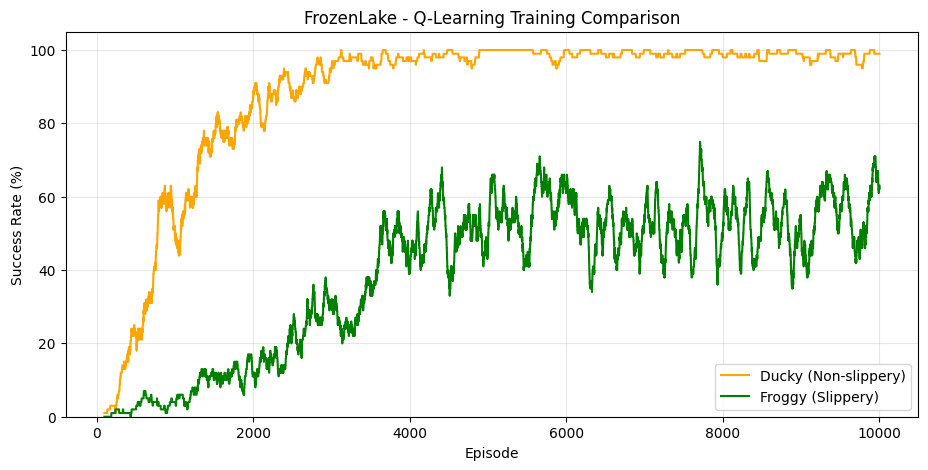

In [9]:
# Ducky ve Froggy'nin egitim basarilarini karsilastirma
plot_training_comparison(history_normal, history_froggy)



### Training Performance

- **Ducky (Non-slippery):** Learns faster and reaches approximately 99% success in the final 100 episodes due to deterministic transitions.
- **Froggy (Slippery):** Learns more slowly, reaching 63% success in the final 100 episodes. Random transitions cause fluctuations even after learning.
- Both agents use the same Q-Learning algorithm and hyperparameters. The main difference is the environment's transition behavior.

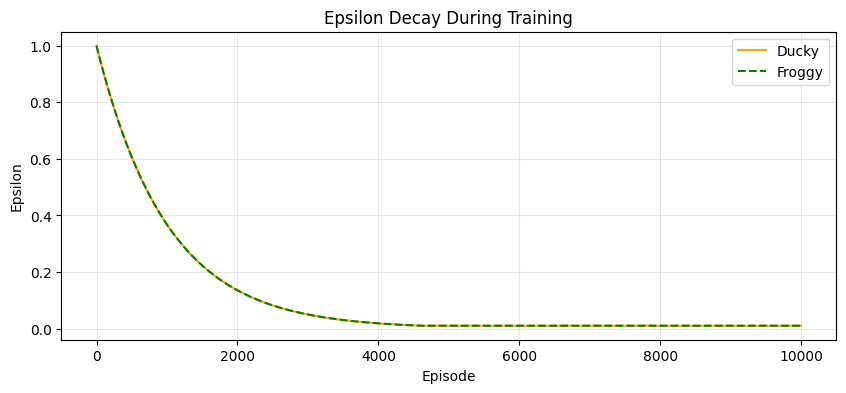

In [10]:
# Ducky ve Froggy'nin kesif oranlarini gorsellestirme
plot_epsilon_decay(history_normal, history_froggy)



### Epsilon Decay

- Both curves overlap because Ducky and Froggy use identical exploration schedules.
- Epsilon decreases from 1.0 toward 0.01, gradually shifting from exploration to exploitation.
- This ensures that the performance differences are not caused by different epsilon schedules.


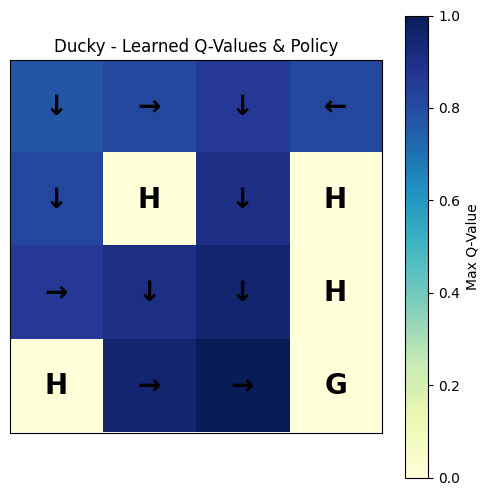

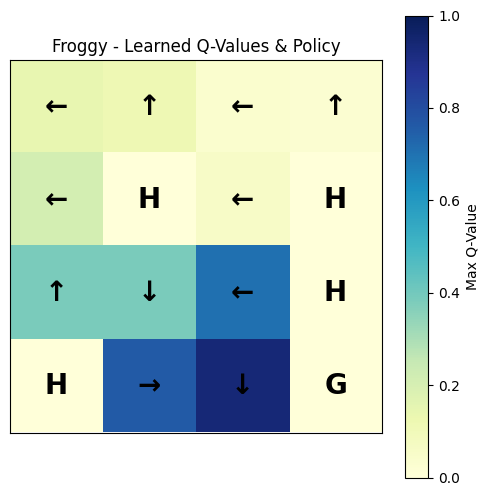

In [11]:
# ajanlarin ogrendigi politikalari gorsellestirme
display_env, _ = create_environment(is_slippery=False)

plot_q_policy(q_table_normal, display_env, "Ducky")
plot_q_policy(q_table_froggy, display_env, "Froggy")

display_env.close()



### Learned Q-Values & Policies

- **Ducky:** Learns a direct path to the goal, with higher Q-values along successful routes.
- **Froggy:** Learns a different policy that considers stochastic transitions and the risk of falling into holes.
- **Colors:** Represent the maximum learned Q-value in each state.
- **Arrows:** Indicate the greedy action selected in each state, not necessarily the actual movement direction in slippery environments.


In [12]:
# ajanlarin oyunlarini gorsellestirme

# Egitilmis ajanin bir oyununu oynatir
def play_episode(q_table, is_slippery=False, seed=SEED):
    env, state = create_environment(is_slippery=is_slippery, seed=seed)

    states = [state]
    terminated = truncated = False
    reward = 0

    while not (terminated or truncated):
        action = greedy_policy(q_table, state)
        state, reward, terminated, truncated, _ = env.step(action)
        states.append(state)

    lake_map = env.unwrapped.desc.astype(str)
    env.close()

    return states, lake_map, reward


# Ajanin hareketlerini GIF olarak olusturur
def create_agent_gif(states, lake_map, agent, filename):
    cell_size = 90
    rows, cols = lake_map.shape
    frames = []

    for step, state in enumerate(states):
        img = Image.new("RGB", (cols * cell_size, rows * cell_size + 40), "#ffffff")
        draw = ImageDraw.Draw(img)

        for row in range(rows):
            for col in range(cols):
                x, y = col * cell_size, row * cell_size
                tile = lake_map[row, col]

                color = {
                    "S": "#dbeafe", "F": "#bfdbfe",
                    "H": "#64748b", "G": "#86efac"
                }[tile]

                draw.rectangle((x, y, x + cell_size, y + cell_size),
                               fill=color, outline="white", width=3)

                if tile == "H":
                    draw.text((x + 38, y + 35), "X", fill="white")
                elif tile == "G":
                    draw.text((x + 38, y + 35), "G", fill="#166534")

        row, col = divmod(state, cols)
        cx = col * cell_size + cell_size // 2
        cy = row * cell_size + cell_size // 2

        if agent == "Ducky":
            # Sari ordek ve gagasi
            draw.ellipse((cx-24, cy-24, cx+24, cy+24), fill="#facc15")
            draw.ellipse((cx+5, cy-12, cx+11, cy-6), fill="black")
            draw.polygon([(cx+20, cy+3), (cx+37, cy+10), (cx+20, cy+16)], fill="#f97316")

        else:
            # Yesil kurbaga ve gozleri
            draw.ellipse((cx-25, cy-22, cx+25, cy+25), fill="#22c55e")

            for dx in (-14, 14):
                draw.ellipse((cx+dx-10, cy-31, cx+dx+10, cy-10), fill="#ffffff")
                draw.ellipse((cx+dx-3, cy-25, cx+dx+3, cy-19), fill="black")

            draw.arc((cx-13, cy-5, cx+13, cy+15), 0, 180, fill="#166534", width=2)

        draw.text((10, rows * cell_size + 12), f"{agent} | Step: {step}", fill="black")
        frames.append(img)

    # Hareketli GIF'i kaydet
    frames[0].save(filename, save_all=True, append_images=frames[1:],
                   duration=350, loop=0, optimize=False)

    # GIF'i Colab'da oynat
    display(IPImage(filename=filename))


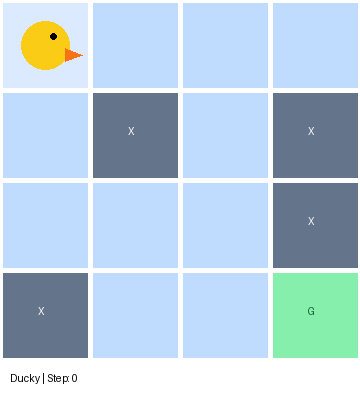

Ducky: Success!


In [13]:

# ducky'nin oynanisi
states_ducky, lake_map, reward_ducky = play_episode(
    q_table_normal,
    is_slippery=False
)

create_agent_gif(states_ducky, lake_map, "Ducky", "ducky.gif")
print("Ducky:", "Success!" if reward_ducky == 1 else "Failed")



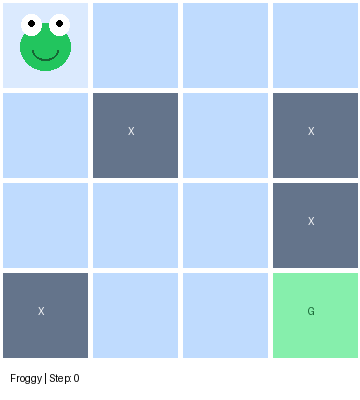

Froggy: Success!


In [14]:
# froggy'nin oynanisi
states_froggy, lake_map, reward_froggy = play_episode(
    q_table_froggy,
    is_slippery=True
)

create_agent_gif(states_froggy, lake_map, "Froggy", "froggy.gif")
print("Froggy:", "Success!" if reward_froggy == 1 else "Failed")

In [15]:

# Ducky ve Froggy'nin bagimsiz test sonuclari
results_ducky = evaluate_agent(q_table_normal, is_slippery=False)
results_froggy = evaluate_agent(q_table_froggy, is_slippery=True)

for name, results in [("Ducky 🐤", results_ducky), ("Froggy 🐸", results_froggy)]:
    print(f"\n{name} - Evaluation Results")
    print(f"Success Rate: {results['success_rate']:.2%}")
    print(f"Mean Reward: {results['mean_reward']:.3f}")
    print(f"Standard Deviation: {results['std_reward']:.3f}")
    print(f"Average Steps: {results['mean_steps']:.2f}")
    print(f"Successful Episode Steps: {results['successful_steps']:.2f}")



Ducky 🐤 - Evaluation Results
Success Rate: 100.00%
Mean Reward: 1.000
Standard Deviation: 0.000
Average Steps: 6.00
Successful Episode Steps: 6.00

Froggy 🐸 - Evaluation Results
Success Rate: 73.70%
Mean Reward: 0.737
Standard Deviation: 0.440
Average Steps: 40.57
Successful Episode Steps: 36.87


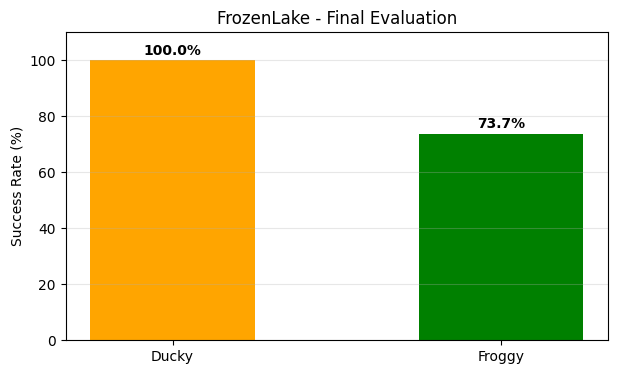

In [16]:

# Ajanlarin test basarilarini karsilastirma
names = ["Ducky", "Froggy"]
success_rates = [results_ducky["success_rate"] * 100,
                 results_froggy["success_rate"] * 100]

plt.figure(figsize=(7, 4))
bars = plt.bar(names, success_rates, color=["orange", "green"], width=0.5)

for bar, rate in zip(bars, success_rates):
    plt.text(bar.get_x() + bar.get_width() / 2, rate + 2,
             f"{rate:.1f}%", ha="center", fontweight="bold")

plt.title("FrozenLake - Final Evaluation")
plt.ylabel("Success Rate (%)")
plt.ylim(0, 110)
plt.grid(axis="y", alpha=0.3)
plt.show()


### Final Conclusion 🐤🐸

This project implemented tabular Q-Learning in two FrozenLake environments to investigate how stochastic transitions affect learning and performance.

- **Ducky (Non-slippery)** achieved a **100% evaluation success rate**, reaching the goal in an average of 6 steps.
- **Froggy (Slippery)** achieved a **73.7% evaluation success rate**, requiring an average of 40.57 steps per episode.
- Both agents were trained for 10,000 episodes using the same hyperparameters and exploration schedule.

The training curves and learned policy visualizations show that deterministic transitions support faster and more stable learning, while stochastic transitions introduce uncertainty and require more cautious decision-making.

**Key Takeaway:** Even with the same Q-Learning algorithm, the environment's transition dynamics significantly influence the learned policy and its performance.

*Based on the Hugging Face Deep RL Course — Unit 2, extended with comparative experiments, policy visualizations, and animated agent demonstrations.*

### 💾 Saving the Trained Agents

The following code saves Ducky's and Froggy's trained Q-Tables as `.npy` files, allowing them to be reused without retraining.

You can also download the pretrained Q-Tables directly from [Hugging Face](https://huggingface.co/zeynpakn/FrozenLake-Q-Learning/tree/main/models).

In [17]:
# egitilmis ajanlarin Q-Table'larini kaydetme
import os

os.makedirs("models", exist_ok=True)

np.save("models/ducky_q_table.npy", q_table_normal)
np.save("models/froggy_q_table.npy", q_table_froggy)

print("Q-Tables saved successfully!")
print("Ducky:", q_table_normal.shape)
print("Froggy:", q_table_froggy.shape)


Q-Tables saved successfully!
Ducky: (16, 4)
Froggy: (16, 4)
